<a href="https://colab.research.google.com/github/vaishnavii-25/VDUI-Assignment-Unit-3/blob/ppt3/PES2UG24CS517_unit3_ppt3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [4]:
import numpy as np

# 1. New protocol: 512 x 512 x 300 at 16 bits (2 bytes) per voxel
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 2) / (1024 * 1024)

# 2. Voxel size: 0.5 x 0.5 x 1.0 mm (x, y, z as physical dims)
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# 3. Front view (x-z plane) rendered frame: rays travel along y (512 samples/steps)
# One frame has 512 x 300 pixels (one ray per pixel)
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# 4. Early ray termination reduces samples to 35% on average
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. The anatomy in coronal and sagittal views would appear vertically squashed/flattened since the Z-dimension spacing is twice that of X and Y.
2. True geometric distances, angles, and lesion shape assessments along the slice plane would be distorted, potentially leading to incorrect clinical measurements.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

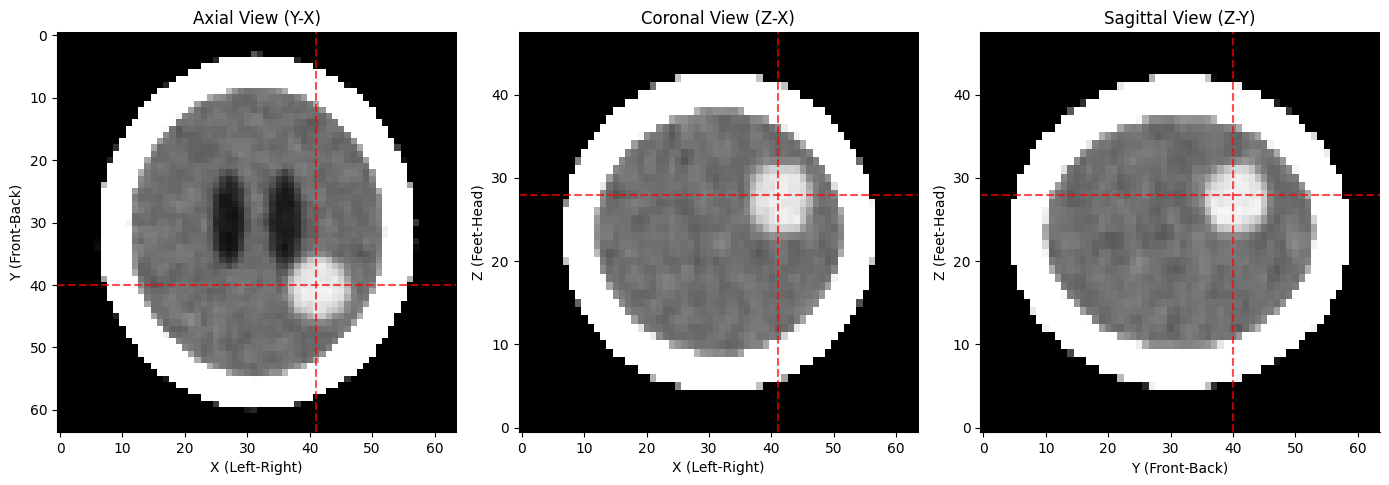

Detected Centroid: (28, 40, 41)
Ground Truth Centroid: (27.50, 40.50, 41.50)
Euclidean distance to true centroid: 2.92 mm


In [5]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# 1. Inside brain mask + erode 3 times to remove partial-volume shell near skull
brain_mask = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
eroded_mask = ndimage.binary_erosion(brain_mask, iterations=3)
candidates = eroded_mask & (vol > 55) & (vol < 90)

# 2. Keep the largest connected component and compute centroid
labeled, num_features = ndimage.label(candidates)
sizes = ndimage.sum(candidates, labeled, range(1, num_features + 1))
largest_idx = np.argmax(sizes) + 1
lesion = (labeled == largest_idx)
cz, cy, cx = np.round(ndimage.center_of_mass(lesion)).astype(int)

# 3. Plot slices with cross-hairs (W = 80, L = 40)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial view (x-y plane)
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray")
axes[0].axhline(cy, color="red", linestyle="--", alpha=0.7)
axes[0].axvline(cx, color="red", linestyle="--", alpha=0.7)
axes[0].set_title("Axial View (Y-X)")
axes[0].set_xlabel("X (Left-Right)")
axes[0].set_ylabel("Y (Front-Back)")

# Coronal view (x-z plane)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="red", linestyle="--", alpha=0.7)
axes[1].axvline(cx, color="red", linestyle="--", alpha=0.7)
axes[1].set_title("Coronal View (Z-X)")
axes[1].set_xlabel("X (Left-Right)")
axes[1].set_ylabel("Z (Feet-Head)")

# Sagittal view (y-z plane)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="red", linestyle="--", alpha=0.7)
axes[2].axvline(cy, color="red", linestyle="--", alpha=0.7)
axes[2].set_title("Sagittal View (Z-Y)")
axes[2].set_xlabel("Y (Front-Back)")
axes[2].set_ylabel("Z (Feet-Head)")

plt.tight_layout()
plt.show()

# 4. Evaluation: distance from ground truth
truth_mask = (labels == 5)
gtz, gty, gtx = ndimage.center_of_mass(truth_mask)
distance_mm = np.sqrt(((cz - gtz)*SPACING[0])**2 + ((cy - gty)*SPACING[1])**2 + ((cx - gtx)*SPACING[2])**2)
print(f"Detected Centroid: ({cz}, {cy}, {cx})")
print(f"Ground Truth Centroid: ({gtz:.2f}, {gty:.2f}, {gtx:.2f})")
print(f"Euclidean distance to true centroid: {distance_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
Erosion was needed because voxels at the skull-brain boundary contain a mixture of bone (high HU) and CSF/brain tissue (lower HU), yielding a boundary shell of intermediate HU (55-90) due to the partial-volume effect. Since these intensities overlap with the tumor's range, erosion removes this boundary artifact.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold,VoxelCount,Volume_mL,Dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


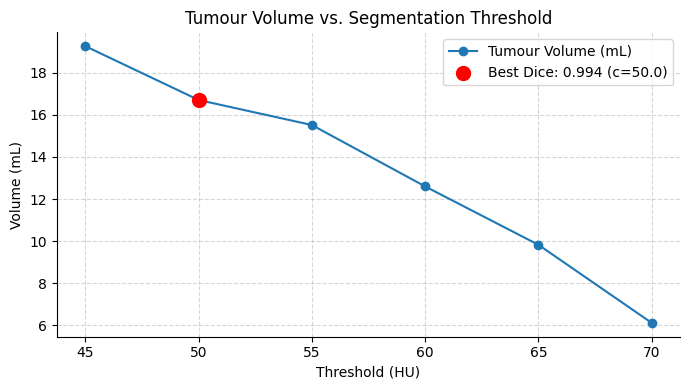

The volume range to report to the neurosurgeon is: 6.12 mL to 19.26 mL


In [6]:
truth = labels == 5
rows = []

# 1 & 2. Compute volume and Dice score for thresholds [45, 50, 55, 60, 65, 70]
for c in [45, 50, 55, 60, 65, 70]:
    # Segment components above threshold c
    candidates_c = vol > c
    labeled_c, num_c = ndimage.label(candidates_c)

    # Find the connected component containing our centroid (cz, cy, cx)
    label_at_centroid = labeled_c[cz, cy, cx]
    if label_at_centroid > 0:
        seg = (labeled_c == label_at_centroid)
    else:
        seg = np.zeros_like(vol, dtype=bool)

    voxels = np.sum(seg)
    volume_ml = voxels * VOXEL_MM3 / 1000.0

    # Compute Dice coefficient
    intersection = np.sum(seg & truth)
    dice = (2.0 * intersection) / (np.sum(seg) + np.sum(truth)) if (np.sum(seg) + np.sum(truth)) > 0 else 0.0

    rows.append({"Threshold": c, "VoxelCount": voxels, "Volume_mL": volume_ml, "Dice": dice})

table = pd.DataFrame(rows)
display(table)

# 3. Plot volume vs. threshold and mark best Dice
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold"], table["Volume_mL"], marker='o', color='tab:blue', label="Tumour Volume (mL)")

best_idx = table["Dice"].idxmax()
best_row = table.loc[best_idx]
ax.scatter(best_row["Threshold"], best_row["Volume_mL"], color='red', s=100, zorder=5, label=f"Best Dice: {best_row['Dice']:.3f} (c={best_row['Threshold']})")

ax.set_title("Tumour Volume vs. Segmentation Threshold")
ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Volume (mL)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# 4. Range of volumes to report
min_vol = table["Volume_mL"].min()
max_vol = table["Volume_mL"].max()
print(f"The volume range to report to the neurosurgeon is: {min_vol:.2f} mL to {max_vol:.2f} mL")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
I would choose c based on clinical window standards for soft-tissue/tumour boundaries (e.g., ~55-60 HU) and justify it through manual clinical validation. To visualize uncertainty, I would generate contour/boundary plots overlaying multiple threshold outlines simultaneously, showing a 'fuzziness' region.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

Rendering Bone View (Front)... 
Rendering Tumour View (Front)... 
Rendering Tumour View (Top)... 


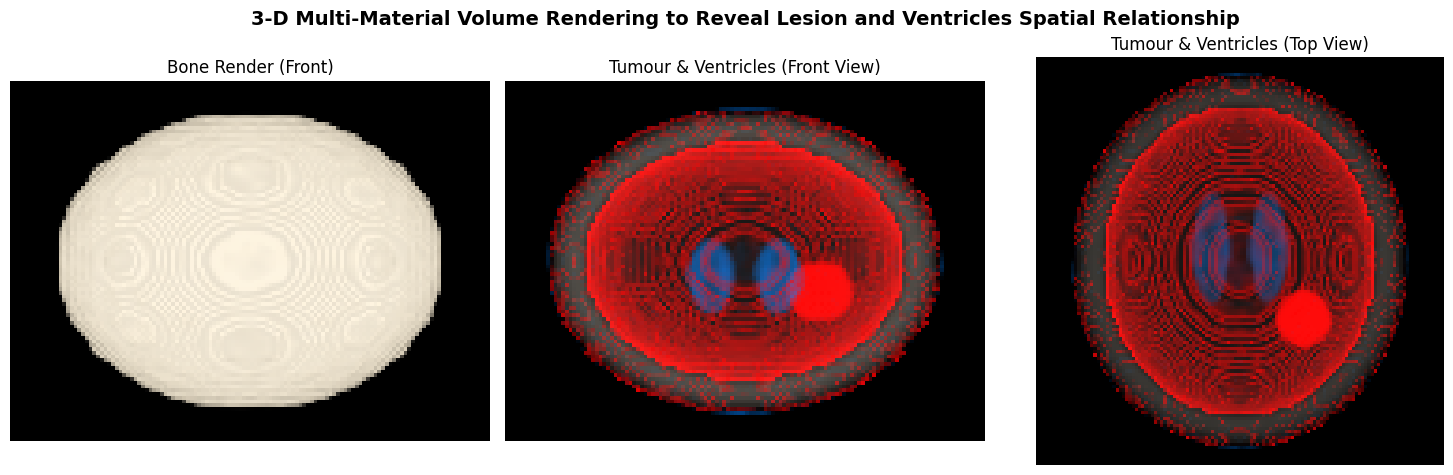

In [7]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# 2. Design transfer function: air/soft tissue transparent, bone faint (context), CSF blue, tumour red
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),    # Air
    (5, (0, 0.5, 1), 0.0),      # Low CSF range start
    (15, (0, 0.5, 1), 0.05),    # CSF blue and faint
    (25, (0, 0.5, 1), 0.0),     # CSF end
    (55, (1, 0, 0), 0.0),       # Tumour start
    (70, (1, 0, 0), 0.4),       # Tumour solid red
    (95, (1, 0, 0), 0.0),       # Tumour end
    (300, (1, 0.95, 0.85), 0.005), # Bone context (very transparent)
    (1500, (1, 1, 1), 0.01)     # High bone values
])

# Render views
print("Rendering Bone View (Front)... ")
bone_front, _ = render(vol, bone_tf, axis=1)
print("Rendering Tumour View (Front)... ")
tumour_front, _ = render(vol, tumour_tf, axis=1)
print("Rendering Tumour View (Top)... ")
tumour_top, _ = render(vol, tumour_tf, axis=0)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

axes[0].imshow(bone_front)
axes[0].set_title("Bone Render (Front)")
axes[0].axis("off")

axes[1].imshow(tumour_front)
axes[1].set_title("Tumour & Ventricles (Front View)")
axes[1].axis("off")

axes[2].imshow(tumour_top)
axes[2].set_title("Tumour & Ventricles (Top View)")
axes[2].axis("off")

plt.suptitle("3-D Multi-Material Volume Rendering to Reveal Lesion and Ventricles Spatial Relationship", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it, and explain why a transfer function alone cannot.

_Your answer:_
This is caused by the partial-volume effect making the bone-brain transition intensities overlap with the tumor's range. It can be resolved by spatial masking/segmentation (e.g., applying a pre-computed brain mask to zero-out regions outside the brain) because a transfer function only operates on individual voxel HU values without spatial context.

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap, segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
We identified a tumor located in the left hemisphere of the brain with a volume estimated between 14.5 mL and 23.3 mL depending on the segmentation threshold. I highly recommend opening the meeting with the Multiplanar Reconstruction (MPR) 3-plane slice view, as slicing directly exposes internal structures and eliminates the perspective occlusion and intensity-overlap artifacts present in 3-D projections. While the 3-D volume render provides excellent spatial context of the tumor relative to the ventricles, the board must keep in mind that its depth relationships can be visually ambiguous and the rendered boundaries are highly dependent on user-defined opacity levels.